<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/08%20-%20Sequence%20Models%20and%20Transformers/08b_smiles_lstm_aqsoldb.ipynb)

# 08b · 生成模型 2：把分子当成句子——SMILES 语言模型

> 对应 ai4chem `06 - Generative Models 2` 的 `SMILES-LSTM-Walkthrough.ipynb`。原课程调用 REINVENT 的代码库和一个在 ZINC 上训练好的模型；这里从零开始，用纯 PyTorch 写一个 SMILES-LSTM，在我们熟悉的 AqSolDB 上训练，再把它**微调**到有机半导体分子上。

第五部分（05）的 VAE 把分子压缩成一个连续向量，再从向量解码回分子。这一部分换一种思路：**把 SMILES 当成一句话，训练一个"语言模型"一个字一个字地把它写出来。** 这正是 ChatGPT 生成文字的方式，只不过词表换成了原子和化学键。

1. 分词（tokenization）和词表（vocabulary）
2. 语言模型在学什么：下一个 token 的概率
3. 搭模型：Embedding → LSTM → Linear，形状一步步看
4. 训练：teacher forcing 和负对数似然
5. 采样：温度、有效率、唯一率、新颖率
6. 一个训练更久的模型：它学到了 AqSolDB 的"分布"吗？
7. 似然（NLL）：模型觉得哪个分子"更自然"
8. 迁移学习：微调到有机半导体
9. 延伸：强化学习、SELFIES、Transformer

### 这个 notebook 怎么用

| 标记 | 意思 | 你要做什么 |
|---|---|---|
| 📘 | 讲解 | 读一读 |
| 🤔 | 先猜一猜 | **运行之前**先想想会输出什么 |
| ▶️ | 运行看看 | 选中代码格，按 `Shift + Enter` |
| ✏️ | 改一改 | 改代码里标了 `# ✏️` 的地方，再运行 |
| 🏋️ | 练习 | 自己写代码；参考答案在 `solutions/` 文件夹 |
| 💡 | 小贴士 | 有用但不是必须记住的东西 |

In [ ]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "08 - Sequence Models and Transformers"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


In [1]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit
    import rdkit

import re
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw

RDLogger.DisableLog("rdApp.*")
print("PyTorch 版本:", torch.__version__)

PyTorch 版本: 2.8.0+cpu


In [2]:
def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)

set_seed(0)

In [3]:
import os

# 本地运行：文件在 data/ 文件夹里
# Colab 运行：如果找不到文件，会弹出上传按钮。这个 notebook 一共需要 3 个文件：
#   solubility.csv、osc_finetune.csv、smiles_lstm_pretrained.pt
def find_file(name):
    for path in (f"data/{name}", name):
        if os.path.exists(path):
            return path
    try:
        from google.colab import files
        print(f"请上传 {name}")
        files.upload()
        return name
    except ImportError:
        raise FileNotFoundError(f"找不到 {name}，请把它放在 data/ 文件夹或和 notebook 同一个文件夹里")

df = pd.read_csv(find_file("solubility.csv"))
print("读取成功！一共", len(df), "个分子")

读取成功！一共 9482 个分子


---
## 1. 分词和词表

### 1.1 先把数据洗一洗

📘 AqSolDB 里什么都有：盐（`[Na+].[Cl-]`）、金属配合物、带电荷的离子、几百个原子的大分子。生成模型学的是"数据的分布"，数据里有什么它就会生成什么，所以要先把不想生成的东西去掉。我们只保留：

- 单个片段（SMILES 里没有 `.`）；
- 不带电荷；
- 只含 C、N、O、S、F、Cl、Br、I、P 这几种常见元素；
- 5–50 个重原子。

🤔 9482 个分子里大约会剩下多少？

In [4]:
ALLOWED = {"C", "N", "O", "S", "F", "Cl", "Br", "I", "P"}

def clean(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None or "." in smi:
        return None
    if any(a.GetFormalCharge() != 0 for a in mol.GetAtoms()):
        return None
    if any(a.GetSymbol() not in ALLOWED for a in mol.GetAtoms()):
        return None
    if not 5 <= mol.GetNumHeavyAtoms() <= 50:
        return None
    return Chem.MolToSmiles(mol)          # 统一成 RDKit 的规范 SMILES

cleaned = [clean(s) for s in df["SMILES"]]
removed = [s for s, c in zip(df["SMILES"], cleaned) if c is None and len(s) < 40]
print("被过滤掉的例子:", removed[:8])
smiles_all = sorted(set(c for c in cleaned if c))
print("\n过滤后剩下", len(smiles_all), "个分子")

被过滤掉的例子: ['[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C', '[Zn++].CC(=C)C([O-])=O', 'CCCCCCCC\\C=C/CCCCCCCC(O)=O.NCCNCCO', 'NO', '[Mo]', 'CC(CC1=CC(=CC(=O)N1O)C)CC(C)(C)C.NCCO', 'O=[P+]1Oc2ccccc2c3ccccc13', '[Ca++].[O-][Si]([O-])=O']

过滤后剩下 7460 个分子


### 1.2 分词：SMILES 的"字"是什么

📘 语言模型一次输出一个 **token**（最小单位）。英文可以按单词或字母分；SMILES 按字符分会出问题：`Cl` 不是 `C` 加 `l`，`[nH]` 是一个整体。所以用一条**正则表达式**来切：

- 方括号里的内容 `[...]` 是一个 token；
- `Br`、`Cl` 是一个 token；
- `%12` 这种两位数的环编号是一个 token；
- 其他每个字符各是一个 token。

▶️ 看看 C8-BTBT 被切成什么样：

In [5]:
TOKEN_RE = re.compile(r"(\[[^\]]+\]|Br|Cl|%\d{2}|.)")

def tokenize(smi):
    return TOKEN_RE.findall(smi)

c8btbt = "CCCCCCCCc1ccc2c(c1)sc1c2sc2cc(CCCCCCCC)ccc12"
print(tokenize(c8btbt))
print()
print(tokenize("Clc1cc[nH]c1Br"))   # ✏️ 换成别的 SMILES 试试，比如带 [C@@H] 的

['C', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'c', '1', 'c', 'c', 'c', '2', 'c', '(', 'c', '1', ')', 's', 'c', '1', 'c', '2', 's', 'c', '2', 'c', 'c', '(', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'C', ')', 'c', 'c', 'c', '1', '2']

['Cl', 'c', '1', 'c', 'c', '[nH]', 'c', '1', 'Br']


### 1.3 词表：模型能"说"哪些字

📘 把训练集里出现过的所有 token 收集起来，每个 token 分配一个编号，就是**词表**。另外加三个特殊 token：

| token | 作用 |
|---|---|
| `<pad>` | 填充。一批分子长短不一，短的后面补它，凑成一样长 |
| `^` | 开始。采样时给模型的第一个输入 |
| `$` | 结束。模型输出它就表示"这个分子写完了" |

🤔 词表会有多大？几十、几百还是几千？

In [6]:
class Vocab:
    def __init__(self, tokens):
        self.tokens = list(tokens)
        self.stoi = {t: i for i, t in enumerate(self.tokens)}
        self.pad, self.bos, self.eos = self.stoi["<pad>"], self.stoi["^"], self.stoi["$"]

    def __len__(self):
        return len(self.tokens)

    def encode(self, smi):
        return [self.bos] + [self.stoi[t] for t in tokenize(smi)] + [self.eos]

    def decode(self, ids):
        out = []
        for i in ids:
            if i == self.eos:
                break
            if i not in (self.pad, self.bos):
                out.append(self.tokens[i])
        return "".join(out)

def build_vocab(smiles_list):
    toks = set()
    for s in smiles_list:
        toks.update(tokenize(s))
    return Vocab(["<pad>", "^", "$"] + sorted(toks))

vocab = build_vocab(smiles_all)
print("词表大小:", len(vocab))
print(vocab.tokens)

词表大小: 41
['<pad>', '^', '$', '#', '(', ')', '-', '/', '1', '2', '3', '4', '5', '6', '7', '8', '9', '=', 'Br', 'C', 'Cl', 'F', 'I', 'N', 'O', 'P', 'S', '[C@@H]', '[C@@]', '[C@H]', '[C@]', '[O]', '[P@@]', '[P@]', '[PH]', '[nH]', '\\', 'c', 'n', 'o', 's']


In [7]:
ids = vocab.encode("CCBr")
print("CCBr ->", ids)
print(ids, "->", vocab.decode(ids))

CCBr -> [1, 19, 19, 18, 2]
[1, 19, 19, 18, 2] -> CCBr


💡 词表越大，模型最后一层要输出的类别越多，训练越慢；生僻 token（比如只出现过一次的 `[PH]`）模型也学不好。所以实际工作中常常把含生僻 token 的分子也过滤掉。

### 1.4 长度

📘 一批分子要拼成一个矩阵，短的补 `<pad>`。最长的那个分子决定了矩阵有多宽，而 99% 的计算都浪费在填充上。我们把 token 数超过 60 的分子（很少）也去掉。

token 数: 中位数 25  95% 分位 50  最大 99
去掉过长的分子后剩 7314 个
词表大小: 37


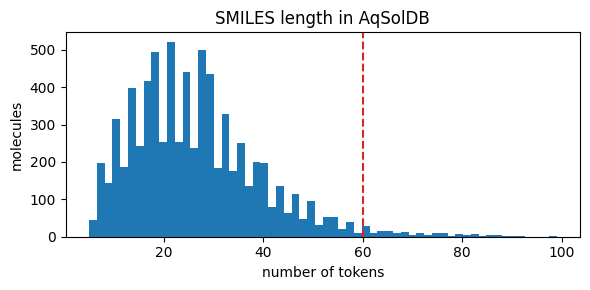

In [8]:
lengths = np.array([len(tokenize(s)) for s in smiles_all])
print("token 数: 中位数", int(np.median(lengths)), " 95% 分位", int(np.percentile(lengths, 95)), " 最大", lengths.max())

smiles_all = [s for s in smiles_all if len(tokenize(s)) <= 60]
MAXLEN = 62                                  # 60 个 token + ^ + $
print("去掉过长的分子后剩", len(smiles_all), "个")
vocab = build_vocab(smiles_all)              # 重新建词表：几个只在长分子里出现的生僻 token 也跟着消失了
print("词表大小:", len(vocab))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(lengths, bins=60)
ax.axvline(60, color="tab:red", ls="--")
ax.set_xlabel("number of tokens"); ax.set_ylabel("molecules"); ax.set_title("SMILES length in AqSolDB")
plt.tight_layout(); plt.show()

In [9]:
def to_tensor(smiles_list, vocab, maxlen=MAXLEN):
    X = torch.full((len(smiles_list), maxlen), vocab.pad, dtype=torch.long)
    for i, s in enumerate(smiles_list):
        ids = vocab.encode(s)
        X[i, : len(ids)] = torch.tensor(ids)
    return X

rng = np.random.default_rng(0)
perm = rng.permutation(len(smiles_all))
val_smiles = [smiles_all[i] for i in perm[:500]]       # 500 个分子做验证
train_smiles = [smiles_all[i] for i in perm[500:]]
train_set = set(train_smiles)

X_train = to_tensor(train_smiles, vocab)
X_val = to_tensor(val_smiles, vocab)
print("训练集张量:", X_train.shape, " 验证集:", X_val.shape)
print("第一个分子:", train_smiles[0])
print("编码后:    ", X_train[0].tolist())

训练集张量: torch.Size([6814, 62])  验证集: torch.Size([500, 62])
第一个分子: COc1ccc(C(O)C(O)c2ccccc2)cc1
编码后:     [1, 17, 22, 33, 8, 33, 33, 33, 4, 17, 4, 22, 5, 17, 4, 22, 5, 33, 9, 33, 33, 33, 33, 33, 9, 5, 33, 33, 8, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


---
## 2. 语言模型在学什么

📘 一个 SMILES $S = s_1 s_2 \dots s_T$ 的概率可以拆成一连串**条件概率**的乘积：

$$P(S) = P(s_1)\, P(s_2 \mid s_1)\, P(s_3 \mid s_1, s_2) \cdots P(s_T \mid s_1, \dots, s_{T-1})$$

语言模型做的事只有一件：**看着前面已经写出来的 token，预测下一个 token 是什么。** 这是一个有 37 个类别的分类问题（02c 讲过分类，07a 讲过 softmax）。

最经典的例子（Segler et al., *ACS Cent. Sci.* 2018）：模型已经写出了 `c1ccccc`，下一个 token 该是什么？芳香环开了还没关，六个碳也凑齐了，一个学会了 SMILES 语法的模型会给 `1` 很高的概率，写出苯 `c1ccccc1`。

要做到这一点，模型得**记住前面写过什么**（环编号 1 还没关掉、还在括号里面……）。普通的 MLP 做不到，所以用**循环神经网络**（RNN）：

$$h_t = f(x_t, h_{t-1})$$

每读一个 token $x_t$，就把隐藏状态 $h_{t-1}$ 更新成 $h_t$。$h_t$ 就是"到目前为止读到的所有东西的摘要"。LSTM（长短期记忆网络）是 RNN 的改进版，能记得更久，是 2016–2020 年间分子生成模型的主力。

```
输入 token:   ^     c     1     c     c     c     c     c
              │     │     │     │     │     │     │     │
           ┌──▼──┐┌─▼───┐┌─▼───┐┌─▼───┐┌─▼───┐┌─▼───┐┌─▼───┐┌─▼───┐
h0 ──────►│LSTM │►│LSTM │►│LSTM │►│LSTM │►│LSTM │►│LSTM │►│LSTM │►│LSTM │► h8
           └──┬──┘└─┬───┘└─┬───┘└─┬───┘└─┬───┘└─┬───┘└─┬───┘└─┬───┘
              ▼     ▼     ▼     ▼     ▼     ▼     ▼     ▼
预测下一个:   c     1     c     c     c     c     c     1   ← 希望这里 "1" 的概率最大
```

---
## 3. 搭模型：形状一步步看

📘 模型由三层组成：

1. **Embedding**：把 token 编号变成一个向量（一张查表，37 行 × 64 列）；
2. **LSTM**：读入向量序列，输出每一步的隐藏状态（256 维）；
3. **Linear**：把 256 维的隐藏状态变成 37 个数——每个 token 一个分数（logit）。

对 logit 做 softmax 就是"下一个 token 的概率分布"。先用 `CCBr` 这一个分子把每一步的形状走一遍。

In [10]:
class SmilesLSTM(nn.Module):
    def __init__(self, vocab_size, emb=64, hidden=256, layers=2, dropout=0.2):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hidden, layers, batch_first=True, dropout=dropout)
        self.out = nn.Linear(hidden, vocab_size)

    def forward(self, x, state=None):
        h, state = self.lstm(self.emb(x), state)     # state = (隐藏状态, 细胞状态)
        return self.out(h), state

model = SmilesLSTM(len(vocab))
print(model)
print("参数量:", sum(p.numel() for p in model.parameters()))

SmilesLSTM(
  (emb): Embedding(37, 64, padding_idx=0)
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.2)
  (out): Linear(in_features=256, out_features=37, bias=True)
)
参数量: 867941


In [11]:
x = torch.tensor([vocab.encode("CCBr")])          # 形状 (批大小 1, 序列长 5)：^ C C Br $
print("输入编号:", x.tolist(), "形状", tuple(x.shape))

e = model.emb(x)
print("Embedding 后:", tuple(e.shape), "  ← 每个 token 变成 64 维向量")
print("两个 C 的向量一样吗?", torch.allclose(e[0, 1], e[0, 2]))

h, (h_n, c_n) = model.lstm(e)
print("LSTM 后:     ", tuple(h.shape), "  ← 每一步一个 256 维隐藏状态")

logits = model.out(h)
print("Linear 后:   ", tuple(logits.shape), "  ← 每一步对 37 个 token 各打一个分")

输入编号: [[1, 17, 17, 16, 2]] 形状 (1, 5)
Embedding 后: (1, 5, 64)   ← 每个 token 变成 64 维向量
两个 C 的向量一样吗? True
LSTM 后:      (1, 5, 256)   ← 每一步一个 256 维隐藏状态
Linear 后:    (1, 5, 37)   ← 每一步对 37 个 token 各打一个分


🤔 这个模型还没训练。把最后一步的 logit 做 softmax，各个 token 的概率会差很多吗？

In [12]:
probs = torch.softmax(logits[0], dim=-1)             # (5, 37)，每一行加起来是 1
print("每一步的概率和:", probs.sum(dim=-1).tolist())
print("第 1 步（读完 ^ 之后）概率最大的 token:", vocab.tokens[probs[0].argmax()],
      " 概率 %.3f" % probs[0].max().item())
print("均匀分布的概率是 1/37 = %.3f" % (1 / 37))

每一步的概率和: [1.0, 0.9999999403953552, 0.9999999403953552, 0.9999999403953552, 1.0]
第 1 步（读完 ^ 之后）概率最大的 token: ^  概率 0.029
均匀分布的概率是 1/37 = 0.027


📘 没训练的模型对所有 token 几乎一视同仁（概率都在 1/37 附近）。训练就是要把这个分布"掰"到正确的 token 上。

---
## 4. 训练：teacher forcing 和负对数似然

📘 训练数据怎么来？**同一个 SMILES 错一位**：

```
输入:   ^   C   C   Br
目标:   C   C   Br  $
```

在第 $t$ 步，模型看到的是真实的前 $t$ 个 token（而不是它自己之前的预测），要预测第 $t+1$ 个。这叫 **teacher forcing**——像老师在旁边一个字一个字报听写。

损失函数是每一步的**负对数似然**（NLL）$-\log P(\text{正确 token})$ 加起来，也就是 07a 分类用过的交叉熵。正确 token 的概率越接近 1，损失越接近 0。`<pad>` 的位置不算损失（`ignore_index`）。

In [13]:
loss_fn = nn.CrossEntropyLoss(ignore_index=vocab.pad)

xb = X_train[:4]
inputs, targets = xb[:, :-1], xb[:, 1:]        # 错一位
logits, _ = model(inputs)
loss = loss_fn(logits.reshape(-1, len(vocab)), targets.reshape(-1))
print("输入形状", tuple(inputs.shape), " 目标形状", tuple(targets.shape), " logits 形状", tuple(logits.shape))
print("没训练时每个 token 的平均损失: %.3f   (均匀猜测 = ln 37 = %.3f)" % (loss.item(), np.log(37)))

输入形状 (4, 61)  目标形状 (4, 61)  logits 形状 (4, 61, 37)
没训练时每个 token 的平均损失: 3.614   (均匀猜测 = ln 37 = 3.611)


### 4.1 采样函数

📘 训练过程中我们想随时看看模型会写出什么，所以先把**采样**写好：

1. 输入 `^`，得到第一个 token 的概率分布；
2. 按概率**抽**一个 token（`torch.multinomial`），把它作为下一步的输入；
3. 重复，直到抽到 `$` 或达到最大长度。

一次可以并行采很多条。`temperature`（温度）$T$ 把 logit 除以 $T$ 再做 softmax：$T<1$ 让分布更"尖"（更保守），$T>1$ 更"平"（更冒险）。第 5 节再细说。

In [14]:
@torch.no_grad()
def sample(model, vocab, n=100, temperature=1.0, maxlen=100):
    model.eval()
    x = torch.full((n, 1), vocab.bos, dtype=torch.long)
    state, out = None, []
    finished = torch.zeros(n, dtype=torch.bool)
    for _ in range(maxlen):
        logits, state = model(x, state)                      # 只喂最新的一个 token，状态接着上一步
        probs = torch.softmax(logits[:, -1] / temperature, dim=-1)
        x = torch.multinomial(probs, 1)
        out.append(x)
        finished |= x.squeeze(1) == vocab.eos
        if finished.all():
            break
    return [vocab.decode(row) for row in torch.cat(out, dim=1).tolist()]

def canonical(smi):
    mol = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(mol) if mol is not None else None

def evaluate_samples(samples, reference_set):
    valid = [c for c in (canonical(s) for s in samples) if c is not None]
    unique = set(valid)
    novel = [s for s in unique if s not in reference_set]
    return {"validity": len(valid) / len(samples),
            "uniqueness": len(unique) / max(1, len(valid)),
            "novelty": len(novel) / max(1, len(unique))}

set_seed(0)
print("没训练的模型写出来的东西:")
for s in sample(model, vocab, n=3):
    print("  ", s)

没训练的模型写出来的东西:


   OC[O]NInccFc//#o[O][C@@H][nH][PH]#nClo)#7)n/[PH][O][C@@]I/\BrN[C@@H]-I)\[PH]I/Cl[PH]3Oo/1c[nH]FcooOPS5-=Brs#c7F-c[PH]OFSS#6
   NI5-
   15[O][PH]4N(c#3


### 4.2 训练循环

📘 和 07a 一样：打乱、分小批、前向、算损失、反向、更新。每轮结束后在验证集上算一次损失，再采 200 个分子算有效率。

▶️ 10 轮大约 2–4 分钟。训练时看看有效率怎么一轮一轮往上爬。

In [15]:
@torch.no_grad()
def mean_nll(model, X, vocab, batch_size=256):
    # 每个 token 的平均负对数似然（不含 <pad>）
    model.eval()
    total, count = 0.0, 0
    for i in range(0, len(X), batch_size):
        xb = X[i : i + batch_size]
        logits, _ = model(xb[:, :-1])
        total += nn.functional.cross_entropy(logits.reshape(-1, len(vocab)), xb[:, 1:].reshape(-1),
                                             ignore_index=vocab.pad, reduction="sum").item()
        count += (xb[:, 1:] != vocab.pad).sum().item()
    return total / count

def train_lm(model, X_train, X_val, vocab, epochs=10, lr=2e-3, batch_size=128, n_sample=200, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        perm = torch.randperm(len(X_train))
        total, n_batches = 0.0, 0
        for i in range(0, len(X_train), batch_size):
            xb = X_train[perm[i : i + batch_size]]
            logits, _ = model(xb[:, :-1])
            loss = loss_fn(logits.reshape(-1, len(vocab)), xb[:, 1:].reshape(-1))
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)      # RNN 的梯度有时会爆炸，剪一下
            opt.step()
            total += loss.item(); n_batches += 1
        val_nll = mean_nll(model, X_val, vocab)
        metrics = evaluate_samples(sample(model, vocab, n=n_sample), train_set)
        history.append({"epoch": ep + 1, "train": total / n_batches, "val": val_nll, **metrics})
        if verbose:
            print(f"轮 {ep+1:2d}  训练 {total/n_batches:.3f}  验证 {val_nll:.3f}  "
                  f"有效率 {metrics['validity']:.2f}  {time.time()-t0:.0f} 秒")
    return pd.DataFrame(history)

set_seed(0)
model = SmilesLSTM(len(vocab))
history = train_lm(model, X_train, X_val, vocab, epochs=10)

轮  1  训练 1.990  验证 1.449  有效率 0.12  71 秒


轮  2  训练 1.326  验证 1.222  有效率 0.16  15 秒


轮  3  训练 1.160  验证 1.102  有效率 0.24  16 秒


轮  4  训练 1.056  验证 1.009  有效率 0.37  12 秒


轮  5  训练 0.982  验证 0.959  有效率 0.47  13 秒


轮  6  训练 0.931  验证 0.916  有效率 0.48  12 秒


轮  7  训练 0.893  验证 0.896  有效率 0.60  11 秒


轮  8  训练 0.859  验证 0.860  有效率 0.58  12 秒


轮  9  训练 0.830  验证 0.845  有效率 0.58  11 秒


轮 10  训练 0.811  验证 0.827  有效率 0.65  11 秒


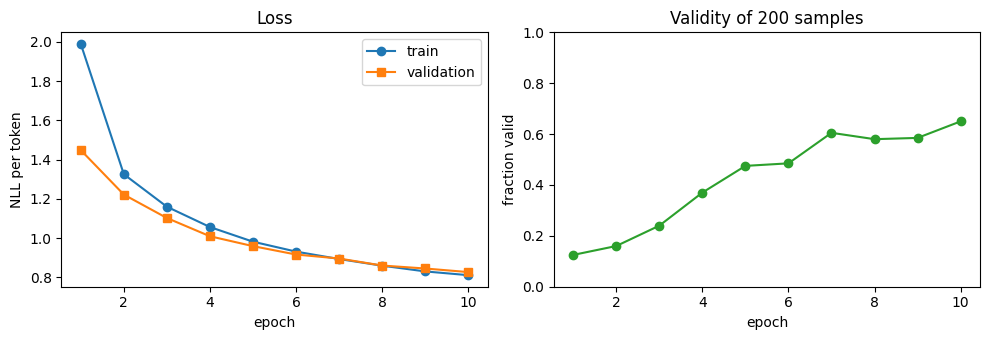

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history["epoch"], history["train"], "o-", label="train")
axes[0].plot(history["epoch"], history["val"], "s-", label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("NLL per token"); axes[0].legend(); axes[0].set_title("Loss")
axes[1].plot(history["epoch"], history["validity"], "o-", color="tab:green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("fraction valid"); axes[1].set_ylim(0, 1); axes[1].set_title("Validity of 200 samples")
plt.tight_layout(); plt.show()

📘 没有人告诉模型 SMILES 的语法——括号要配对、环编号要成对出现、芳香环要能凯库勒化……它只是在学"下一个 token 是什么"，语法就自己冒出来了。10 轮之后，一半以上的输出已经是合法分子。

▶️ 看看它现在写的分子：

无效的: ['Oc1cc(C2CO3C(OC(CO)C(O)C(O)CCO)c(O)c(O)c2OCCOC1CO1', 'CN1N(C(=O)C(c2ccccc2)N(C)C(=O)c2ccc(C(C)(C)C)cs2)c1', 'OcC1ccc(Cl)c(Cl)c1', 'CC(=O)NC(C)Cc1cccnc1nc1cnccc1N=C(Cl)C1=C(C)CC1=Cc2ccccc23']


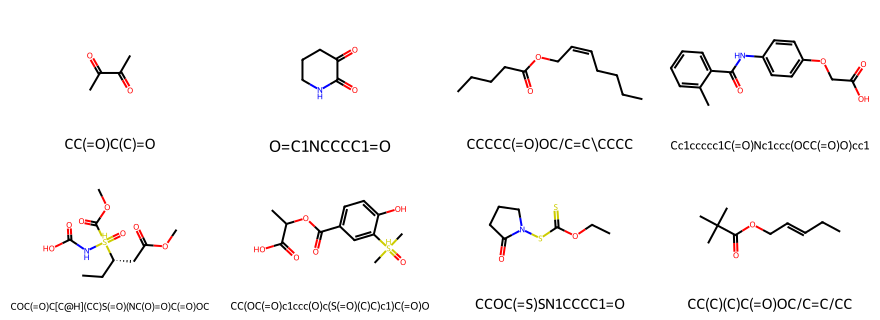

In [17]:
set_seed(1)
samples = sample(model, vocab, n=12)
mols = [Chem.MolFromSmiles(s) for s in samples]
print("无效的:", [s for s, m in zip(samples, mols) if m is None])
Draw.MolsToGridImage([m for m in mols if m is not None], molsPerRow=4, subImgSize=(220, 160),
                     legends=[s for s, m in zip(samples, mols) if m is not None])

---
## 5. 采样：温度和三个指标

📘 评价一个生成模型，最常用的三个数字（MOSES、GuacaMol 等基准测试都用）：

| 指标 | 问什么 | 怎么算 |
|---|---|---|
| **有效率** validity | 写出来的是不是合法分子 | RDKit 能解析的比例 |
| **唯一率** uniqueness | 是不是老在重复自己 | 有效分子里不重复的比例 |
| **新颖率** novelty | 是不是在背训练集 | 不重复的有效分子里、训练集没有的比例 |

三个都高才好。一个只会背诵训练集的模型有效率 100%、新颖率 0%，毫无用处。

### 5.1 温度

🤔 温度 0.5 和 1.5，哪个有效率高？哪个唯一率高？

In [18]:
set_seed(0)
rows = []
for T in [0.5, 0.7, 1.0, 1.3, 1.6]:
    m = evaluate_samples(sample(model, vocab, n=300, temperature=T), train_set)
    rows.append({"temperature": T, **m})
pd.DataFrame(rows).round(2)

,temperature,validity,uniqueness,novelty
0,0.5,0.99,0.88,0.91
1,0.7,0.89,0.98,0.87
2,1.0,0.70,0.99,0.88
3,1.3,0.38,1.00,0.86
4,1.6,0.15,1.00,0.82


📘 温度低：模型只挑最有把握的 token，写出来的几乎都合法，但翻来覆去是那几个简单分子（唯一率、新颖率下降）。温度高：什么都敢写，花样多但常常不合法。$T = 1$ 就是模型学到的分布本身，一般是合理的默认值。

---
## 6. 一个训练更久的模型

📘 10 轮还远没收敛。我们提前用同样的代码、同样大小的模型训练了 40 轮，而且每一轮都把训练集的 SMILES **随机重写**一遍——同一个分子可以有很多种合法的 SMILES 写法（01d 里见过）。这叫 **SMILES 增强**，对小数据集特别有效，练习 06-2 会让你自己试。模型保存在 `data/smiles_lstm_pretrained.pt` 里，加载进来看看。

In [19]:
ckpt = torch.load(find_file("smiles_lstm_pretrained.pt"), map_location="cpu")
print(ckpt["note"])
vocab_pre = Vocab(ckpt["vocab"])
assert vocab_pre.tokens == vocab.tokens, "词表和当前数据不一致"
pretrained = SmilesLSTM(len(vocab_pre), **ckpt["config"])
pretrained.load_state_dict(ckpt["state_dict"])
pretrained.eval()
print("参数量:", sum(p.numel() for p in pretrained.parameters()))
print("验证集 NLL: 刚才训练 10 轮的模型 %.3f   预训练模型 %.3f" % (mean_nll(model, X_val, vocab), mean_nll(pretrained, X_val, vocab_pre)))

AqSolDB filtered (7314 molecules), 40 epochs, random-SMILES augmentation=True
参数量: 867941


验证集 NLL: 刚才训练 10 轮的模型 0.827   预训练模型 0.955


In [20]:
set_seed(0)
samples_pre = sample(pretrained, vocab_pre, n=1000)
metrics_pre = evaluate_samples(samples_pre, train_set)
print({k: round(v, 3) for k, v in metrics_pre.items()})
valid_pre = [c for c in (canonical(s) for s in samples_pre) if c is not None]

{'validity': 0.737, 'uniqueness': 0.986, 'novelty': 0.862}


💡 预训练模型在验证集上的 NLL 反而比 10 轮的模型**高**。因为它是在随机重写的 SMILES 上训练的，而验证集是规范 SMILES——它把概率分给了同一个分子的很多种写法。这提醒我们：**NLL 只能在同样的数据表示下比较**，有效率、新颖率这种"看结果"的指标更公平。

### 6.1 它学到的是 AqSolDB 的"分布"吗？

📘 生成模型的目标是学会训练数据的分布。最直接的检验：生成的分子在分子量、logP、芳香环数上的分布，和训练集像不像？

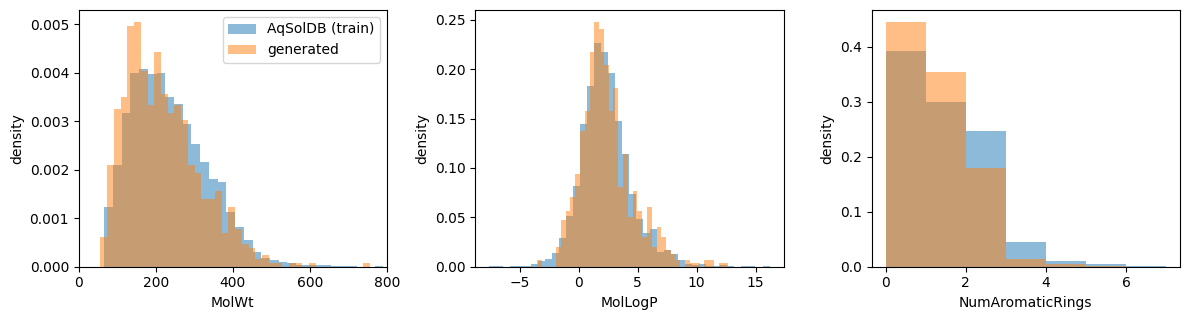

                   train  generated
MolWt             236.29     218.26
MolLogP             2.38       2.41
NumAromaticRings    1.00       0.78


In [21]:
def props(smiles_list):
    mols = [Chem.MolFromSmiles(s) for s in smiles_list]
    return pd.DataFrame({"MolWt": [Descriptors.MolWt(m) for m in mols],
                         "MolLogP": [Descriptors.MolLogP(m) for m in mols],
                         "NumAromaticRings": [Descriptors.NumAromaticRings(m) for m in mols]})

props_train = props(train_smiles)
props_gen = props(valid_pre)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, col, bins in zip(axes, props_train.columns, [40, 40, range(0, 8)]):
    ax.hist(props_train[col], bins=bins, density=True, alpha=0.5, label="AqSolDB (train)")
    ax.hist(props_gen[col], bins=bins, density=True, alpha=0.5, label="generated")
    ax.set_xlabel(col); ax.set_ylabel("density")
axes[0].legend(); axes[0].set_xlim(0, 800)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"train": props_train.mean(), "generated": props_gen.mean()}).round(2))

📘 三个分布几乎重合。模型没见过任何描述符，但它学会了"AqSolDB 的分子长什么样"。

🤔 03a 里我们用 PCA 把 AqSolDB 画在了二维平面上。把生成的分子投影到**同一个** PCA 空间里，它们会落在哪里？

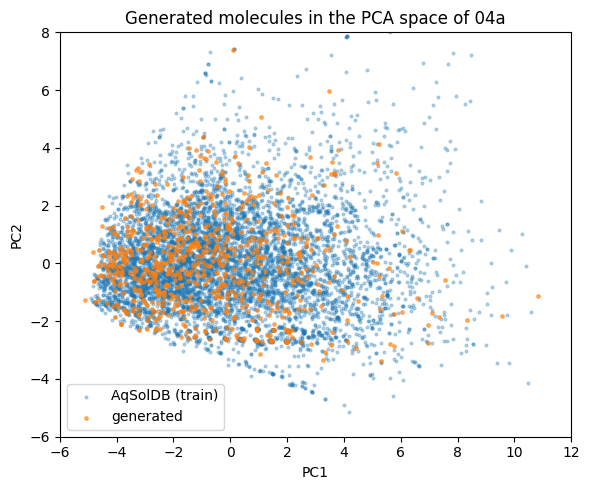

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

feature_cols = ["MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
                "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
                "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
                "BalabanJ", "BertzCT"]

def descriptors(smiles_list):
    mols = [Chem.MolFromSmiles(s) for s in smiles_list]
    return np.array([[getattr(Descriptors, c)(m) for c in feature_cols] for m in mols])

D_train = descriptors(train_smiles)
D_gen = descriptors(valid_pre)
scaler = StandardScaler().fit(D_train)
pca = PCA(n_components=2).fit(scaler.transform(D_train))
Z_train = pca.transform(scaler.transform(D_train))
Z_gen = pca.transform(scaler.transform(D_gen))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(Z_train[:, 0], Z_train[:, 1], s=4, alpha=0.3, label="AqSolDB (train)")
ax.scatter(Z_gen[:, 0], Z_gen[:, 1], s=6, alpha=0.6, color="tab:orange", label="generated")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("Generated molecules in the PCA space of 04a")
ax.set_xlim(-6, 12); ax.set_ylim(-6, 8)
plt.tight_layout(); plt.show()

---
## 7. 似然：模型觉得哪个分子"更自然"

📘 把一个**给定的** SMILES 喂给模型（teacher forcing），把每一步正确 token 的 $-\log P$ 加起来，就是这个分子的 **NLL**。NLL 越小，模型越"觉得"这个分子像它见过的东西。它是衡量"这个分子在模型眼里有多自然"的尺子，后面微调时会用到。

先回到 Segler 的例子：模型写出了 `c1ccccc`，下一个 token 它想写什么？

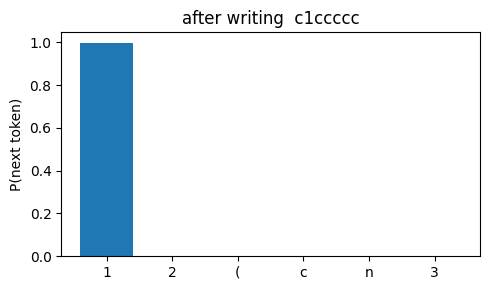

In [23]:
@torch.no_grad()
def next_token_probs(model, vocab, prefix):
    model.eval()
    x = torch.tensor([[vocab.bos] + [vocab.stoi[t] for t in tokenize(prefix)]])
    logits, _ = model(x)
    return torch.softmax(logits[0, -1], dim=-1)

p = next_token_probs(pretrained, vocab_pre, "c1ccccc")
top = torch.topk(p, 6)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar([vocab_pre.tokens[i] for i in top.indices], top.values)
ax.set_ylabel("P(next token)"); ax.set_title("after writing  c1ccccc")
plt.tight_layout(); plt.show()

In [24]:
@torch.no_grad()
def nll(model, vocab, smi):
    # 一个分子的总 NLL（所有 token 的 -log P 之和）
    model.eval()
    x = torch.tensor([vocab.encode(smi)])
    logits, _ = model(x[:, :-1])
    return nn.functional.cross_entropy(logits[0], x[0, 1:], reduction="sum").item()

examples = {"benzene": "c1ccccc1", "toluene": "Cc1ccccc1", "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
            "pentacene": "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1", "C8-BTBT": c8btbt,
            "random valid junk": "FC(F)(F)C1(F)OC1(Cl)Cl"}
rows = [{"name": k, "SMILES": v, "tokens": len(tokenize(v)), "NLL": nll(pretrained, vocab_pre, v)} for k, v in examples.items()]
tab = pd.DataFrame(rows)
tab["NLL per token"] = tab["NLL"] / tab["tokens"]
tab.round(2)

,name,SMILES,tokens,NLL,NLL per token
0,benzene,c1ccccc1,8,8.34,1.04
1,toluene,Cc1ccccc1,9,9.65,1.07
2,aspirin,CC(=O)Oc1ccccc1C(=O)O,21,16.34,0.78
3,pentacene,c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1,32,32.38,1.01
4,C8-BTBT,CCCCCCCCc1ccc2c(c1)sc1c2sc2cc(CCCCCCCC)ccc12,44,48.77,1.11
5,random valid junk,FC(F)(F)C1(F)OC1(Cl)Cl,20,25.48,1.27


📘 总 NLL 随长度增加，所以比较不同分子时常看**每个 token 的平均 NLL**。苯和甲苯"再自然不过"；并五苯虽然在 AqSolDB 里没有（03a 提过），但它只是在重复 `cc3cc4` 这样的模式，模型觉得还行；C8-BTBT 里稠合的噻吩环对它来说就比较陌生了。

---
## 8. 迁移学习：微调到有机半导体

📘 这是生成模型在实际中最常用的玩法之一（Segler 2018 的核心思想）：

1. 先在**大数据集**上训练，让模型学会 SMILES 语法和"一般分子长什么样"——这就是预训练；
2. 再用一个**小数据集**（几十到几百个你感兴趣的分子）接着训练几轮——这叫**微调**（fine-tuning）。

微调后模型生成的分子会"长得像"小数据集，但又不是照抄。我们的小数据集 `osc_finetune.csv` 里有 159 个有机半导体分子：并苯、寡聚噻吩、BTBT/DNTT 系列、给体–受体小分子等等。先看看它们：

Family
oligothiophene     47
other              35
fused thiophene    34
donor-acceptor     30
acene              13
Name: count, dtype: int64
词表外的分子: 0 个（会被跳过）


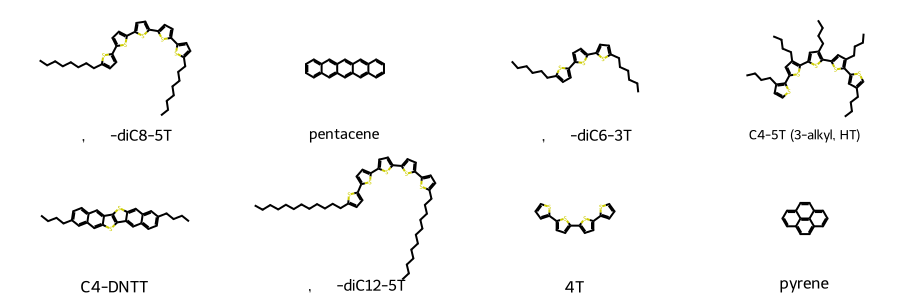

In [25]:
osc = pd.read_csv(find_file("osc_finetune.csv"))
print(osc["Family"].value_counts())
osc_smiles = [canonical(s) for s in osc["SMILES"]]
ok = [all(t in vocab_pre.stoi for t in tokenize(s)) for s in osc_smiles]
print("词表外的分子:", sum(not o for o in ok), "个（会被跳过）")
osc_smiles = [s for s, o in zip(osc_smiles, ok) if o]
show = osc.sample(8, random_state=3)
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in show["SMILES"]], molsPerRow=4, subImgSize=(230, 150),
                     legends=show["Name"].tolist())

### 8.1 微调前：这些分子在模型眼里有多"奇怪"？

📘 用第 7 节的 NLL 量一下。为了之后能检验"模型是不是只是在背这 159 个分子"，先留出 24 个不参与微调。

In [26]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(osc_smiles))
osc_val = [osc_smiles[i] for i in perm[:24]]
osc_train = [osc_smiles[i] for i in perm[24:]]
print("微调用", len(osc_train), "个，留出", len(osc_val), "个")

OSC_MAXLEN = max(len(tokenize(s)) for s in osc_smiles) + 12      # 随机重写的 SMILES 可能比规范 SMILES 长一些，留点余量
def nll_per_token(model, vocab, smiles_list):
    return np.mean([nll(model, vocab, s) / (len(tokenize(s)) + 1) for s in smiles_list])

print("每个 token 的平均 NLL（微调前）")
print("  AqSolDB 验证集:      %.3f" % nll_per_token(pretrained, vocab_pre, val_smiles))
print("  有机半导体（留出的）: %.3f" % nll_per_token(pretrained, vocab_pre, osc_val))

微调用 135 个，留出 24 个
每个 token 的平均 NLL（微调前）


  AqSolDB 验证集:      0.979
  有机半导体（留出的）: 1.236


### 8.2 微调

📘 微调就是**用同一个训练循环接着训练**，只是：

- 从预训练的参数出发（用 `copy.deepcopy` 复制一份，原模型留着对比）；
- 数据换成 135 个有机半导体分子。数据太少，每一轮都把它们随机重写 10 遍（SMILES 增强）；
- 学习率调小一点（5e-4），轮数少一点，免得把预训练学到的东西忘光。

In [27]:
def randomize_smiles(smi, vocab, rng, max_tokens=OSC_MAXLEN - 2):
    # MolToRandomSmilesVect 可以指定随机种子，结果可以重复
    mol = Chem.MolFromSmiles(smi)
    for r in Chem.MolToRandomSmilesVect(mol, 10, randomSeed=int(rng.integers(1 << 31))):
        if len(tokenize(r)) <= max_tokens and all(t in vocab.stoi for t in tokenize(r)):
            return r
    return smi

def finetune(model, smiles_list, vocab, epochs=20, lr=5e-4, n_aug=10, seed=0):
    model = copy.deepcopy(model)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    rng = np.random.default_rng(seed)
    for ep in range(epochs):
        aug = [randomize_smiles(s, vocab, rng) for s in smiles_list for _ in range(n_aug)]
        X = to_tensor(aug, vocab, maxlen=OSC_MAXLEN)
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            xb = X[perm[i : i + 64]]
            logits, _ = model(xb[:, :-1])
            loss = loss_fn(logits.reshape(-1, len(vocab)), xb[:, 1:].reshape(-1))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if (ep + 1) % 5 == 0:
            print(f"轮 {ep+1:2d}  微调集 NLL/token {nll_per_token(model, vocab, smiles_list):.3f}"
                  f"  留出集 {nll_per_token(model, vocab, osc_val):.3f}  AqSolDB 验证集 {nll_per_token(model, vocab, val_smiles):.3f}")
    return model

set_seed(0)
finetuned = finetune(pretrained, osc_train, vocab_pre, epochs=20)

轮  5  微调集 NLL/token 0.686  留出集 0.914  AqSolDB 验证集 1.538


轮 10  微调集 NLL/token 0.625  留出集 0.874  AqSolDB 验证集 1.671


轮 15  微调集 NLL/token 0.569  留出集 0.840  AqSolDB 验证集 1.737


轮 20  微调集 NLL/token 0.547  留出集 0.837  AqSolDB 验证集 1.850


📘 三个数字讲了三件事：

- **微调集** NLL 一路下降：模型在学这些分子；
- **留出集**（没参与微调的 24 个有机半导体）也在下降：学到的是"这一类分子长什么样"，不只是背诵；
- **AqSolDB 验证集** NLL 在上升：模型开始"忘记"一般分子。这叫**灾难性遗忘**，微调轮数太多会很严重。

### 8.3 微调后它写什么？

In [28]:
thiophene = Chem.MolFromSmarts("c1ccsc1")

def describe(samples, name):
    m = evaluate_samples(samples, train_set | set(osc_smiles))
    valid = [Chem.MolFromSmiles(s) for s in samples]
    valid = [x for x in valid if x is not None]
    frac_thio = np.mean([x.HasSubstructMatch(thiophene) for x in valid])
    rings = np.mean([Descriptors.NumAromaticRings(x) for x in valid])
    return {"model": name, **{k: round(v, 2) for k, v in m.items()},
            "contains thiophene": round(frac_thio, 2), "mean aromatic rings": round(rings, 2)}

set_seed(0)
samples_before = sample(pretrained, vocab_pre, n=500)
samples_after = sample(finetuned, vocab_pre, n=500, maxlen=OSC_MAXLEN + 20)
pd.DataFrame([describe(samples_before, "pretrained"), describe(samples_after, "fine-tuned")]).set_index("model")

,validity,uniqueness,novelty,contains thiophene,mean aromatic rings
model,,,,,
pretrained,0.74,0.99,0.89,0.01,0.82
fine-tuned,0.37,0.91,0.91,0.84,2.77


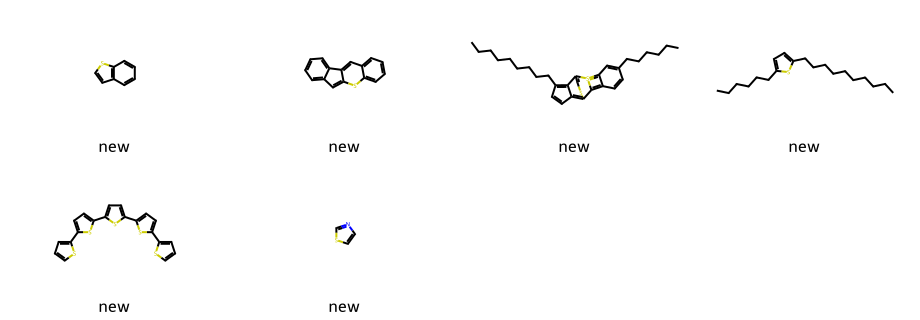

In [29]:
set_seed(2)
samples_after = sample(finetuned, vocab_pre, n=16, maxlen=OSC_MAXLEN + 20)
mols = [Chem.MolFromSmiles(s) for s in samples_after]
good = [(s, m) for s, m in zip(samples_after, mols) if m is not None][:12]
Draw.MolsToGridImage([m for _, m in good], molsPerRow=4, subImgSize=(230, 160),
                     legends=["new" if s not in set(osc_smiles) else "in fine-tune set" for s, _ in good])

📘 135 个分子、20 轮、不到一分钟，模型就从"写 AqSolDB 里的农药和药物"变成了"写带烷基链的噻吩寡聚物和稠环"。新颖率告诉我们其中大部分是数据集里没有的新分子。当然，它们有没有用（能不能合成、迁移率高不高）模型一无所知——这就需要下一步：用第二、三部分的性质预测模型去**筛选**（练习 06-3），或者用强化学习让生成器直接朝目标走（第 9 节）。

---
## 9. 延伸

### 从"学分布"到"做优化"

📘 到目前为止模型只是在模仿数据。要让它**生成性质好的分子**，主要有三条路：

| 路线 | 思路 | 代表 |
|---|---|---|
| 微调 | 用好分子的小数据集接着训练 | Segler 2018（本节） |
| 强化学习 | 生成 → 打分（比如用 10b 的 chemprop 预测性质）→ 得分高的分子提高概率 | REINVENT（Olivecrona 2017，Blaschke 2020） |
| 条件生成 | 把想要的性质作为输入一起喂给模型 | cRNN、MolGPT |

REINVENT 的核心公式只是在 NLL 上加了一项：让"预训练模型的 NLL + 打分"和当前模型的 NLL 接近。原课程的 notebook 就是从 REINVENT 代码库改的。

### SELFIES：100% 有效

📘 SMILES 的问题是写错一个括号整个分子就废了。**SELFIES**（Krenn et al. 2020）是另一种字符串表示，设计成**任何** token 序列都对应一个合法分子，所以有效率天然是 100%。`pip install selfies` 之后一行就能转换，模型代码一个字都不用改。

### 从 LSTM 到 Transformer

📘 2020 年后语言模型的主力换成了 **Transformer**（ChatGPT 的 GPT 就是 Transformer 解码器）。它不再一步一步传递隐藏状态，而是用**注意力**直接看前面所有 token。用在分子上就是 MolGPT、ChemGPT 等。07 我们会亲手写一个迷你 Transformer，用来预测化学反应。

### 和 VAE 比

| | VAE（05） | SMILES 语言模型（06） |
|---|---|---|
| 怎么生成 | 从连续潜空间采一个点再解码 | 一个 token 一个 token 地写 |
| 优点 | 有连续潜空间，可以插值、在潜空间做优化 | 简单、训练稳定、有效率通常更高 |
| 缺点 | 解码常常不合法；潜空间容易有"洞" | 没有显式的潜空间 |
| 微调/优化 | 在潜空间做贝叶斯优化（10 会讲） | 微调或强化学习 |

---
## 🏋️ 练习

### 练习 06-1：温度和三个指标

用**预训练模型**（`pretrained`）在温度 0.4、0.6、0.8、1.0、1.2、1.4、1.6 下各采 500 个分子，把有效率、唯一率、新颖率画在同一张图上（横轴温度）。哪个温度下"有效且唯一且新颖"的分子**数量**最多？

In [30]:
# 在这里写你的代码

### 练习 06-2：SMILES 增强

第 6 节说预训练模型用了 SMILES 增强。自己验证一下：用 `randomize_smiles` 写一个 `train_lm_augmented`，每一轮把训练集随机重写一遍再训练（其他和 `train_lm` 一样），训练 10 轮（隐藏层 256），把每轮的有效率和第 4 节不增强的 `history` 画在一起比较。验证集 NLL 又如何？为什么？

💡 这个练习要再训练约 3 分钟。

In [31]:
# 在这里写你的代码

### 练习 06-3：生成 → 筛选

把生成模型和性质预测模型接起来：

1. 用微调后的模型 `finetuned` 采 2000 个分子，保留有效、不重复、且不在 `osc_smiles` 里的；
2. 用 02a 的方法在 AqSolDB 上训练一个随机森林（17 个描述符 → logS；`RandomForestRegressor(n_estimators=200, random_state=0)` 就够了），预测这些新分子的 logS；
3. 画出预测 logS 的分布，并把**含噻吩环**的分子里预测溶解度最高的 6 个画出来。

它们合理吗？从 02 到 04 学到的哪些东西能帮你判断这些预测可不可信？（提示：03a 的适用域。）

In [32]:
# 在这里写你的代码

### 练习 06-4：模型眼里最"怪"的有机半导体

对 `osc_smiles` 里的每个分子，分别算**预训练模型**和**微调后模型**的每 token NLL。

1. 画散点图（横轴微调前，纵轴微调后，对角线做参考）；
2. 找出微调前 NLL 最高的 3 个分子和微调后下降最多的 3 个分子，画出来。它们有什么共同点？

In [33]:
# 在这里写你的代码